## Curva ROC AUC

=== EVALUACIÓN NUMÉRICA ROC-AUC ===
ROC-AUC Score: 0.9981


/home/patricio/Documentos/github/ciencia-de-datos/.venv/lib/python3.13/site-packages/sklearn/utils/_plotting.py:175: FutureWarning: `**kwargs` is deprecated and will be removed in 1.9. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(


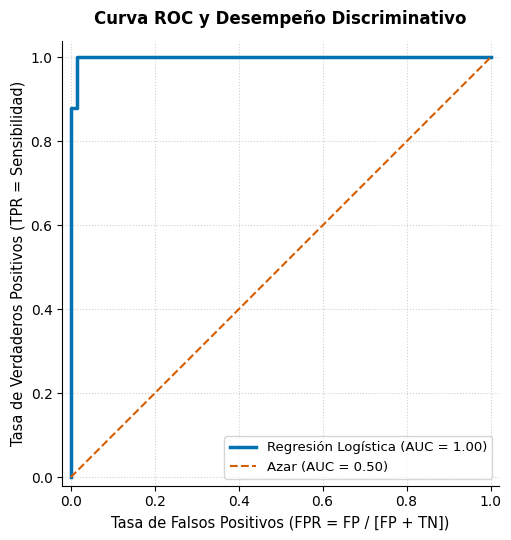

In [22]:
"""
Cálculo e Interpretación de ROC-AUC en Scikit-Learn.
Clasificación Binaria.
"""

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve, RocCurveDisplay

# 1. Carga de datos y partición estratificada
X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# 2. Preprocesamiento y ajuste del modelo
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

clf = LogisticRegression(random_state=42)
clf.fit(X_train_scaled, y_train)

# 3. Obtención de probabilidades para la clase positiva (y = 1)
# IMPORTANTE: Se toma la columna con índice 1
y_probs = clf.predict_proba(X_test_scaled)[:, 1]

# 4. Cálculo numérico de ROC-AUC
auc_score = roc_auc_score(y_test, y_probs)
print("=== EVALUACIÓN NUMÉRICA ROC-AUC ===")
print(f"ROC-AUC Score: {auc_score:.4f}")

# 5. Visualización mediante RocCurveDisplay (Fondo blanco plano)
fig, ax = plt.subplots(figsize=(7.5, 5.5), facecolor='white')
ax.set_facecolor('white')

# Renderizado directo desde el estimador
RocCurveDisplay.from_estimator(
    clf,
    X_test_scaled,
    y_test,
    name="Regresión Logística",
    color="#0072b2",
    linewidth=2.5,
    ax=ax
)

# Línea base de azar puro (diagonal de 45 grados)
ax.plot([0, 1], [0, 1], color="#d55e00", linestyle="--", linewidth=1.5, label="Azar (AUC = 0.50)")

ax.set_title("Curva ROC y Desempeño Discriminativo", fontsize=12, fontweight="bold", pad=12)
ax.set_xlabel("Tasa de Falsos Positivos (FPR = FP / [FP + TN])", fontsize=10.5)
ax.set_ylabel("Tasa de Verdaderos Positivos (TPR = Sensibilidad)", fontsize=10.5)
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.04)
ax.grid(True, linestyle=":", alpha=0.6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(frameon=True, facecolor='white', loc='lower right', fontsize=9.5)

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.datasets import load_iris

# Carga de dataset multiclase (3 clases)
X_multi, y_multi = load_iris(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(X_multi, y_multi, test_size=0.3, random_state=42, stratify=y_multi)

modelo_multi = LogisticRegression(max_iter=1000, random_state=42).fit(X_tr, y_tr)

# Matriz completa de probabilidades (N_test x 3)
probs_multi = modelo_multi.predict_proba(X_te)

# Cálculo OvR Macro
auc_ovr_macro = roc_auc_score(y_te, probs_multi, multi_class='ovr', average='macro')
# Cálculo OvR Ponderado por soporte
auc_ovr_weighted = roc_auc_score(y_te, probs_multi, multi_class='ovr', average='weighted')

print(f"ROC-AUC Multiclase (OvR Macro)   : {auc_ovr_macro:.4f}")
print(f"ROC-AUC Multiclase (OvR Weighted): {auc_ovr_weighted:.4f}")

In [ ]:
"""
Evaluación de Modelos de Clasificación vía Curva ROC-AUC.
Librería: scikit-learn y matplotlib.
"""

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, roc_auc_score

# 1. Simulación de datos con clases desbalanceadas (30% positivos, 70% negativos)
X, y = make_classification(
    n_samples=1200, n_features=10, n_informative=5,
    n_redundant=2, weights=[0.7, 0.3], random_state=42
)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# 2. Ajuste del modelo y obtención de probabilidades continuas
clf = LogisticRegression(random_state=42)
clf.fit(X_train, y_train)

# Obtenemos P(y=1|x) para el conjunto de prueba
y_probs = clf.predict_proba(X_test)[:, 1]

# 3. Cálculo de la curva ROC y el AUC
fpr, tpr, thresholds = roc_curve(y_test, y_probs)
auc = roc_auc_score(y_test, y_probs)

# 4. Cálculo del umbral óptimo mediante el Índice de Youden (J = TPR - FPR)
youden_idx = np.argmax(tpr - fpr)
opt_fpr = fpr[youden_idx]
opt_tpr = tpr[youden_idx]
opt_thresh = thresholds[youden_idx]

print(f"Área Bajo la Curva (AUC):        {auc:.4f}")
print(f"Umbral Óptimo de Youden:         {opt_thresh:.4f}")
print(f"Sensibilidad en Umbral Óptimo:   {opt_tpr*100:.1f}%")
print(f"FPR en Umbral Óptimo:            {opt_fpr*100:.1f}%")

# 5. Generación Gráfica (Fondo blanco plano y paleta contrastada)
fig, ax = plt.subplots(figsize=(8, 6), facecolor='white')
ax.set_facecolor('white')

# Curva del modelo y sombreado del área
ax.plot(fpr, tpr, color='#0072b2', linewidth=2.5, label=f'Modelo Logístico (AUC = {auc:.3f})')
ax.fill_between(fpr, 0, tpr, color='#0072b2', alpha=0.15, label='Área Bajo la Curva (AUC)')

# Línea base de azar
ax.plot([0, 1], [0, 1], color='#d55e00', linestyle='--', linewidth=1.6, label='Clasificador Aleatorio (AUC = 0.500)')

# Punto óptimo de Youden
ax.scatter([opt_fpr], [opt_tpr], color='#222222', s=70, zorder=5)
ax.annotate(
    f'Punto Óptimo (Youden)\nTPR: {opt_tpr:.2f} | FPR: {opt_fpr:.2f}\nUmbral: {opt_thresh:.2f}',
    xy=(opt_fpr, opt_tpr),
    xytext=(opt_fpr + 0.12, opt_tpr - 0.18),
    arrowprops=dict(facecolor='#222222', shrink=0.08, width=1.2, headwidth=6),
    fontweight='bold', fontsize=9.5, color='#222222',
    bbox=dict(boxstyle='round,pad=0.4', facecolor='white', edgecolor='#cccccc')
)

ax.set_title(f'Curva ROC: Modelo Logístico Alcanza un AUC de {auc:.2f}', fontsize=12, fontweight='bold', pad=10)
ax.set_xlabel('Tasa de Falsos Positivos (FPR = FP / [FP + TN])', fontsize=10.5)
ax.set_ylabel('Tasa de Verdaderos Positivos (TPR = TP / [TP + FN])', fontsize=10.5)
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.04)
ax.grid(True, linestyle=':', alpha=0.6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(frameon=True, facecolor='white', loc='lower right', fontsize=9.5)

plt.tight_layout()
plt.show()

### Comparación Experimental en Desbalance Severo

In [ ]:
"""
Evaluación Comparativa ROC-AUC vs PR-AUC bajo Desbalance Extremo.
Dataset: 99% Negativos (Legítimos) vs. 1% Positivos (Fraude).
"""

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve, auc

# 1. Simulación de datos con 99% negativos y 1% positivos
X, y = make_classification(
    n_samples=10000, n_features=15, n_informative=6, n_redundant=3,
    weights=[0.99, 0.01], random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# 2. Ajuste del modelo de Regresión Logística (con ponderación balanceada)
clf = LogisticRegression(class_weight='balanced', random_state=42)
clf.fit(X_train, y_train)

# Probabilidades continuas predichas para la clase positiva
y_probs = clf.predict_proba(X_test)[:, 1]

# 3. Cálculo de métricas ROC y PR
fpr, tpr, _ = roc_curve(y_test, y_probs)
roc_auc = roc_auc_score(y_test, y_probs)

precision, recall, _ = precision_recall_curve(y_test, y_probs)
pr_auc = auc(recall, precision)
prevalencia = np.mean(y_test)  # Línea base de azar en PR (~0.01)

print(f"ROC-AUC Score: {roc_auc:.4f}  (Aparenta ser casi perfecto)")
print(f"PR-AUC Score:  {pr_auc:.4f}  (Refleja la degradación por falsos positivos)")
print(f"Prevalencia de clase positiva: {prevalencia*100:.2f}%")

# 4. Generación Gráfica Comparativa (Fondo Blanco Plano)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), facecolor='white')

# Panel 1: Curva ROC
ax1.set_facecolor('white')
ax1.plot(fpr, tpr, color='#0072b2', linewidth=2.5, label=f'Modelo (ROC-AUC = {roc_auc:.3f})')
ax1.plot([0, 1], [0, 1], color='#d55e00', linestyle='--', linewidth=1.5, label='Azar (AUC = 0.500)')
ax1.set_title('1. Curva ROC (Aparenta Éxito Engañoso)', fontsize=12, fontweight='bold', pad=10)
ax1.set_xlabel('Tasa de Falsos Positivos (FPR = FP / [FP + TN])', fontsize=10.5)
ax1.set_ylabel('Recall / TPR (TP / [TP + FN])', fontsize=10.5)
ax1.set_xlim(-0.02, 1.02)
ax1.set_ylim(-0.02, 1.04)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.legend(frameon=True, facecolor='white', loc='lower right', fontsize=9.5)

# Panel 2: Curva Precision-Recall
ax2.set_facecolor('white')
ax2.plot(recall, precision, color='#009e73', linewidth=2.5, label=f'Modelo (PR-AUC = {pr_auc:.3f})')
ax2.axhline(prevalencia, color='#e69f00', linestyle='--', linewidth=1.5,
            label=f'Línea Base = Prevalencia ({prevalencia*100:.1f}%)')
ax2.set_title('2. Curva Precision-Recall (Revela el Impacto de Falsos Positivos)', fontsize=12, fontweight='bold', pad=10)
ax2.set_xlabel('Recall / Exhaustividad (TP / [TP + FN])', fontsize=10.5)
ax2.set_ylabel('Precisión (TP / [TP + FP])', fontsize=10.5)
ax2.set_xlim(-0.02, 1.02)
ax2.set_ylim(-0.02, 1.04)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.legend(frameon=True, facecolor='white', loc='upper right', fontsize=9.5)

fig.suptitle('Impacto del Desbalance Extremo de Clases (99% Negativos vs 1% Positivos)',
             fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

### Precision-recall

=== EVALUACIÓN DE DESEMPEÑO BAJO DESBALANCE ===
Prevalencia de clase positiva en test: 2.47%
Average Precision (AP / PR-AUC oficial): 0.1379
Área Trapezoidal (auc):                 0.1310


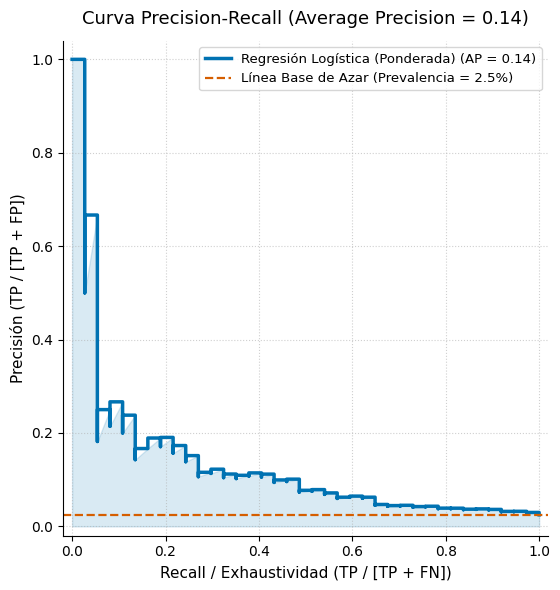

In [19]:
"""
Evaluación de Modelos con Precision-Recall AUC (PR-AUC).
Librería: scikit-learn y matplotlib.
"""

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score,
    auc,
    PrecisionRecallDisplay
)

# ==============================================================================
# 1. Simulación de Datos Desbalanceados (98% Normal vs. 2% Anomalías/Fraude)
# ==============================================================================
X, y = make_classification(
    n_samples=5000,
    n_features=12,
    n_informative=6,
    n_redundant=2,
    weights=[0.98, 0.02],  # Prevalencia del 2%
    random_state=42
)

# Partición estratificada para preservar la proporción de positivos en test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# ==============================================================================
# 2. Preprocesamiento y Ajuste del Clasificador
# ==============================================================================
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Ajuste con balanceo de pesos para compensar el desbalance muestral
clf = LogisticRegression(class_weight='balanced', random_state=42)
clf.fit(X_train_scaled, y_train)

# Extracción de probabilidades continuas para la clase positiva P(y=1|x)
y_scores = clf.predict_proba(X_test_scaled)[:, 1]

# ==============================================================================
# 3. Cálculo de PR-AUC y Average Precision (AP)
# ==============================================================================
# A. Método estándar de Scikit-Learn: Average Precision
ap_score = average_precision_score(y_test, y_scores)

# B. Método trapezoidal manual
precision, recall, thresholds = precision_recall_curve(y_test, y_scores)
area_trapecio = auc(recall, precision)

prevalencia_test = np.mean(y_test)

print("=== EVALUACIÓN DE DESEMPEÑO BAJO DESBALANCE ===")
print(f"Prevalencia de clase positiva en test: {prevalencia_test * 100:.2f}%")
print(f"Average Precision (AP / PR-AUC oficial): {ap_score:.4f}")
print(f"Área Trapezoidal (auc):                 {area_trapecio:.4f}")

# ==============================================================================
# 4. Generación Gráfica con PrecisionRecallDisplay (Fondo Blanco Plano)
# ==============================================================================
fig, ax = plt.subplots(figsize=(8, 6), facecolor="white")
ax.set_facecolor("white")

# Renderizado mediante la API de visualización de scikit-learn
display = PrecisionRecallDisplay.from_predictions(
    y_test,
    y_scores,
    name="Regresión Logística (Ponderada)",
    color="#0072b2",
    linewidth=2.5,
    ax=ax
)

# Sombreado bajo la curva
ax.fill_between(recall, precision, color="#0072b2", alpha=0.15)

# Línea base del clasificador aleatorio (Prevalencia poblacional)
ax.axhline(
    prevalencia_test,
    color="#d55e00",
    linestyle="--",
    linewidth=1.6,
    label=f"Línea Base de Azar (Prevalencia = {prevalencia_test*100:.1f}%)"
)

# Estilizado y anotaciones pedagógicas
ax.set_title(
    f"Curva Precision-Recall (Average Precision = {ap_score:.2f})",
    fontsize=13,
    fontweight="normal",
    pad=12
)
ax.set_xlabel("Recall / Exhaustividad (TP / [TP + FN])", fontsize=11)
ax.set_ylabel("Precisión (TP / [TP + FP])", fontsize=11)
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.04)
ax.grid(True, linestyle=":", alpha=0.6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(frameon=True, facecolor='white', loc='upper right', fontsize=9.5)

plt.tight_layout()
plt.show()

### Matriz de confusion

In [ ]:
"""
Evaluación de Modelos mediante Matriz de Confusión.
Librerías: scikit-learn y matplotlib.
"""

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score

# 1. Simulación de datos industriales (85% Normal  vs. 15% Falla Crítica)
X, y = make_classification(
    n_samples=1000, n_features=8, n_informative=5, n_redundant=2,
    weights=[0.85, 0.15], random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# 2. Ajuste del modelo con ponderación de clases para mitigar desbalance
clf = LogisticRegression(class_weight='balanced', random_state=42)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

# 3. Cálculo formal de la Matriz de Confusión
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

# Normalización por fila (porcentaje de acierto por clase real)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

print("=== RECUENTO MATRICIAL ===")
print(f"Verdaderos Negativos (TN): {tn}")
print(f"Falsos Positivos     (FP): {fp}")
print(f"Falsos Negativos     (FN): {fn}")
print(f"Verdaderos Positivos (TP): {tp}\n")

# 4. Cálculo de Métricas Derivadas
print("=== REPORTE DE CLASIFICACIÓN DETALLADO ===")
print(classification_report(y_test, y_pred, target_names=['Normal (0)', 'Falla (1)']))

# 5. Visualización Gráfica (Fondo Blanco Plano y Paleta Contrastada)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), facecolor='white')

# Panel 1: Mapa térmico de la Matriz de Confusión
ax1.set_facecolor('white')
cmap_blues = sns.light_palette("#0072b2", as_cmap=True)

sns.heatmap(cm, annot=False, cmap=cmap_blues, cbar=False, ax=ax1, linewidths=2, linecolor='white')

# Textos dentro de cada celda con recuento y porcentaje
textos = [
    [f"TN\n{tn}\n({cm_norm[0, 0]*100:.1f}%)", f"FP\n{fp}\n({cm_norm[0, 1]*100:.1f}%)"],
    [f"FN\n{fn}\n({cm_norm[1, 0]*100:.1f}%)", f"TP\n{tp}\n({cm_norm[1, 1]*100:.1f}%)"]
]

for i in range(2):
    for j in range(2):
        color = "white" if cm[i, j] > (cm.max() / 2) else "#222222"
        ax1.text(j + 0.5, i + 0.5, textos[i][j], ha='center', va='center',
                 fontsize=11, fontweight='bold', color=color)

ax1.set_title('1. Matriz de Confusión de Clasificación (N=300)', fontsize=12, fontweight='bold', pad=14)
ax1.set_xlabel('Clase Predicha por el Modelo', fontsize=11, labelpad=8)
ax1.set_ylabel('Clase Real (Ground Truth)', fontsize=11, labelpad=8)
ax1.set_xticklabels(['Normal (0)', 'Falla (1)'], fontsize=10, fontweight='bold')
ax1.set_yticklabels(['Normal (0)', 'Falla (1)'], fontsize=10, fontweight='bold', rotation=0)

# Panel 2: Barras horizontales de métricas derivadas
ax2.set_facecolor('white')
metricas = ['Exactitud\n(Accuracy)', 'Precisión\n(PPV)', 'Exhaustividad\n(Recall)', 'F1-Score']
valores = [
    accuracy_score(y_test, y_pred) * 100,
    precision_score(y_test, y_pred) * 100,
    recall_score(y_test, y_pred) * 100,
    f1_score(y_test, y_pred) * 100
]
colores = ['#0072b2', '#009e73', '#e69f00', '#cc79a7']

barras = ax2.barh(metricas, valores, color=colores, height=0.48)
ax2.set_xlim(0, 115)
ax2.set_xlabel('Porcentaje (%)', fontsize=11)
ax2.set_title('2. Métricas de Rendimiento Derivadas', fontsize=12, fontweight='bold', pad=14)
ax2.grid(axis='x', linestyle=':', alpha=0.6)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

for b, v in zip(barras, valores):
    ax2.text(v + 2, b.get_y() + b.get_height()/2, f'{v:.1f}%', va='center', ha='left',
             fontsize=10, fontweight='bold', color='#222222')

fig.suptitle('Evaluación Diagnóstica Mediante Matriz de Confusión', fontsize=15, fontweight='bold', y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

In [ ]:
# MAtriz confusion multiclasificación
"""
Matriz de Confusión Multiclase y Promedios (Macro, Micro, Weighted).
Librerías: scikit-learn, matplotlib y seaborn.
"""

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

# 1. Simulación de datos multiclase desbalanceados (N = 1200)
# Clases: 0 = Normal (70%), 1 = Alerta (20%), 2 = Parada Crítica (10%)
X, y = make_classification(
    n_samples=1200,
    n_features=10,
    n_informative=6,
    n_classes=3,
    n_clusters_per_class=1,
    weights=[0.70, 0.20, 0.10],
    random_state=42
)

nombres_clases = ['Normal (A)', 'Alerta (B)', 'Crítica (C)']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# 2. Ajuste de Regresión Logística Multiclase (Multinomial / Cross-Entropy)
clf = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

# 3. Cálculo de la Matriz de Confusión 3x3
cm = confusion_matrix(y_test, y_pred)

# 4. Reporte de Clasificación Oficial de Scikit-Learn
print("=== REPORTE DE CLASIFICACIÓN DETALLADO ===")
print(classification_report(y_test, y_pred, target_names=nombres_clases, digits=3))

# 5. Comparación explícita de tipos de promedio para F1-Score
f1_macro = f1_score(y_test, y_pred, average='macro')
f1_weighted = f1_score(y_test, y_pred, average='weighted')
f1_micro = f1_score(y_test, y_pred, average='micro')

print("=== COMPARACIÓN DE ESTRATEGIAS DE PROMEDIO (F1-SCORE) ===")
print(f"F1-Score Macro    (Equidad entre clases)       : {f1_macro:.3f}")
print(f"F1-Score Weighted (Ponderado por prevalencia)  : {f1_weighted:.3f}")
print(f"F1-Score Micro    (Global agregado = Accuracy) : {f1_micro:.3f}")

# 6. Visualización Gráfica (Fondo Blanco Plano y Paleta Accessible)
fig, ax = plt.subplots(figsize=(7.5, 6), facecolor='white')
ax.set_facecolor('white')

# Mapa térmico en tonos azules
cmap_blues = sns.light_palette("#0072b2", as_cmap=True)
sns.heatmap(cm, annot=True, fmt='d', cmap=cmap_blues, cbar=False, ax=ax,
            linewidths=2, linecolor='white', annot_kws={'fontsize': 12, 'fontweight': 'bold'})

ax.set_title("Matriz de Confusión Multiclase (3 Estados de Planta)",
             fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Clase Predicha por el Estimador", fontsize=11, labelpad=8)
ax.set_ylabel("Clase Real (Ground Truth)", fontsize=11, labelpad=8)
ax.set_xticklabels(nombres_clases, fontsize=10, fontweight='bold')
ax.set_yticklabels(nombres_clases, fontsize=10, fontweight='bold', rotation=0)

plt.tight_layout()
plt.show()